# EnergyAI — Phase 2 exploratory analysis

This notebook explores validated hourly electricity demand for Île-de-France. Canonical timestamps remain in UTC; local calendar analysis uses `Europe/Paris`.

In [4]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from energyai.eda import generate_eda_report

DATA_PATH = ROOT / "data" / "processed" / "2024" / "load_hourly.parquet"
REPORT_DIR = ROOT / "reports" / "phase2" / "figures"
hourly = pd.read_parquet(DATA_PATH)
hourly.head()

,region_code,timestamp_utc,load_mw,sample_count,source_dataset,source_nature,ingested_at_utc
0,11,2024-01-01 00:00:00+00:00,7720.5,2,eco2mix-regional-cons-def,Données définitives,2026-11-06 00:36:53.284384+00:00
1,11,2024-01-01 01:00:00+00:00,7409.5,2,eco2mix-regional-cons-def,Données définitives,2026-11-06 00:36:53.284384+00:00
2,11,2024-01-01 02:00:00+00:00,7178.0,2,eco2mix-regional-cons-def,Données définitives,2026-11-06 00:36:53.284384+00:00
3,11,2024-01-01 03:00:00+00:00,7050.5,2,eco2mix-regional-cons-def,Données définitives,2026-11-06 00:36:53.284384+00:00
4,11,2024-01-01 04:00:00+00:00,7027.5,2,eco2mix-regional-cons-def,Données définitives,2026-11-06 00:36:53.284384+00:00


## Data integrity

Before interpreting patterns, confirm the UTC range, missing targets, and hourly sample counts.

In [5]:
pd.Series(
    {
        "rows": len(hourly),
        "first_utc": hourly["timestamp_utc"].min(),
        "last_utc": hourly["timestamp_utc"].max(),
        "missing_load": hourly["load_mw"].isna().sum(),
        "complete_hours": hourly["load_mw"].notna().sum(),
    }
)

rows                                   8784
first_utc         2024-01-01 00:00:00+00:00
last_utc          2024-12-31 23:00:00+00:00
missing_load                              1
complete_hours                         8783
dtype: object

## Demand patterns

The report covers the yearly series, load distribution, weekday/weekend profiles, monthly seasonality, a weekday-hour heatmap, and lag autocorrelation. Every axis includes its unit and timezone interpretation.

# Phase 2 exploratory findings

The figures use UTC for the canonical time series and Europe/Paris for calendar interpretation.

1. Average demand peaks around local hour **12:00**, supporting hour-of-day features.
2. Mean weekday load is **7,534 MW**, compared with **6,946 MW** on weekends.
3. Monthly average demand is highest in month **1** and lowest in month **8**.
4. The 168-hour UTC-lag autocorrelation is **0.878**, supporting a weekly naïve baseline.
5. The curated table contains **1 incomplete hourly target(s)**; they remain missing.
6. UTC lags are stable and leakage-safe, but a 168-hour UTC lag is not always the same local clock hour across DST changes.

These observations describe association, not causation. The source is a revised historical archive and does not prove historical publication availability; Phase 2 assumes a conservative two-hour measurement delay for cutoff checks.


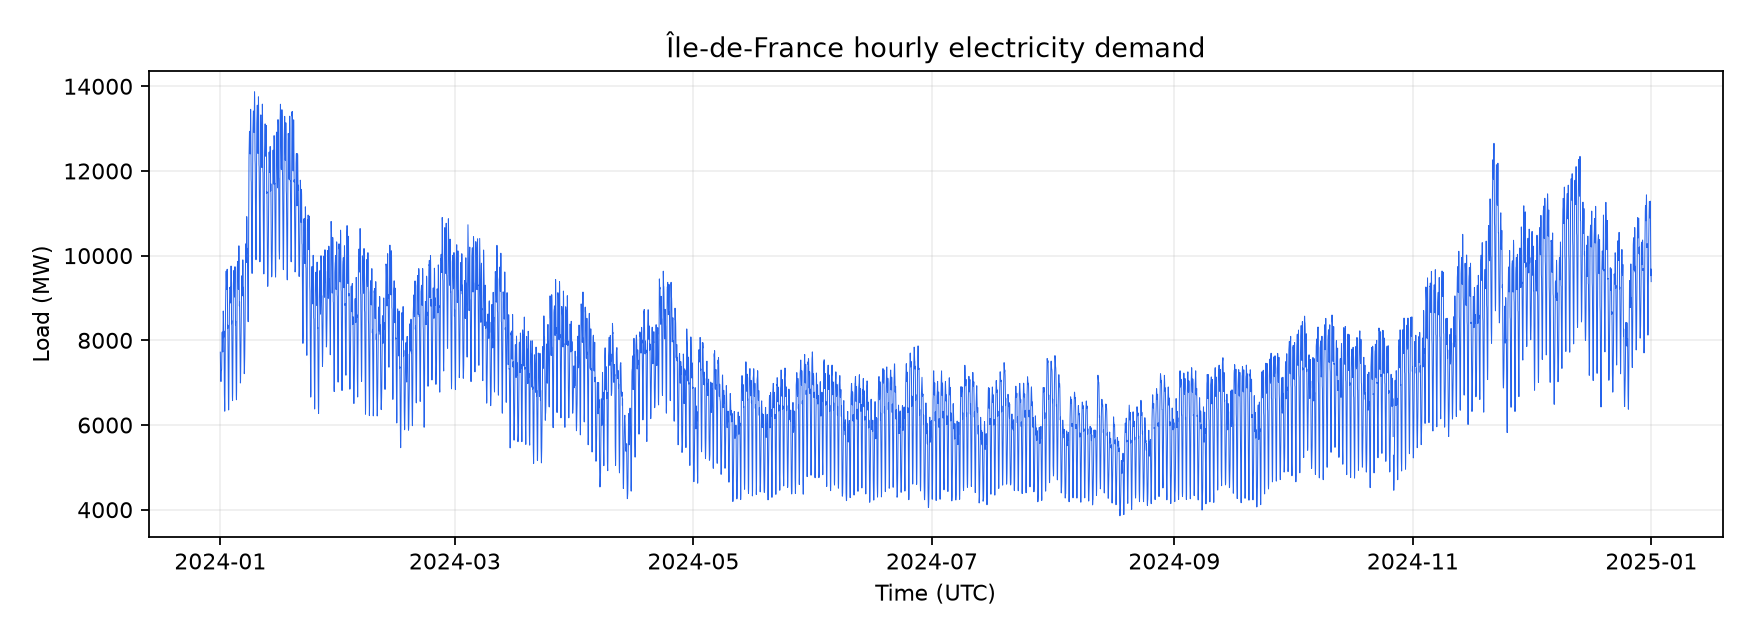

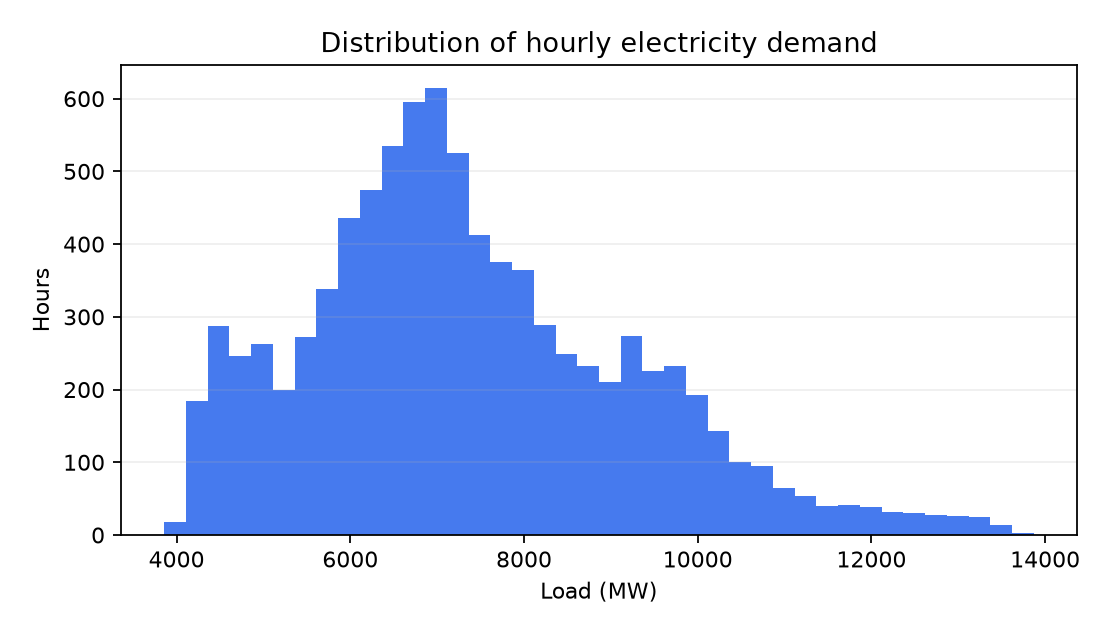

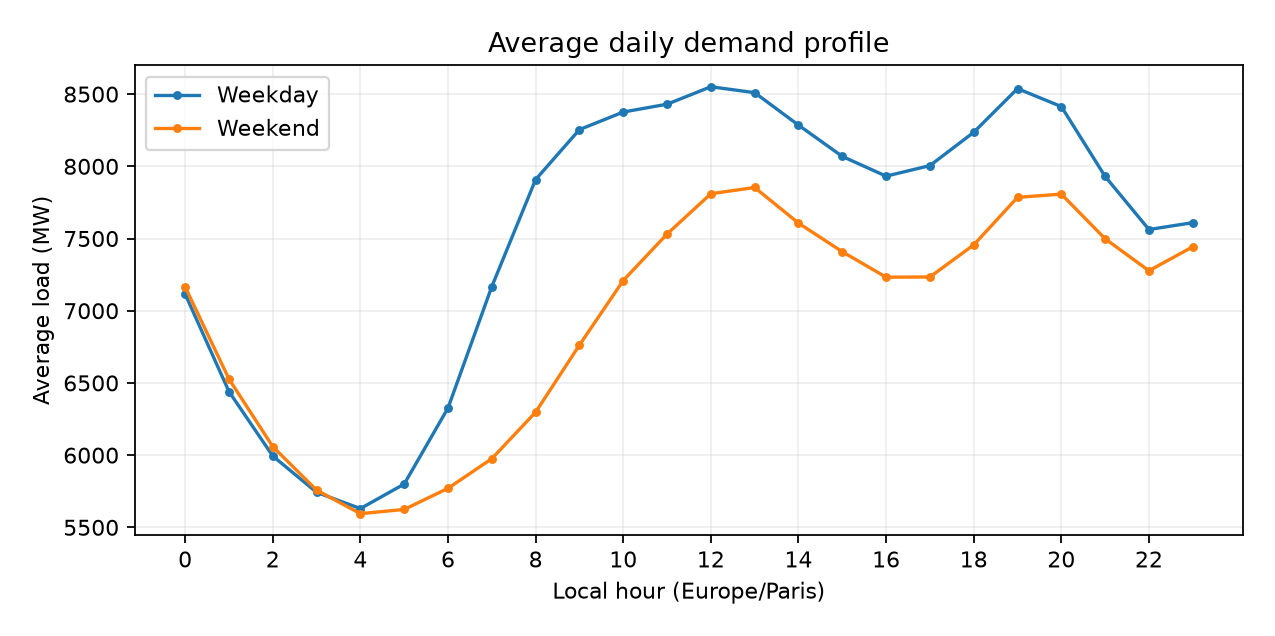

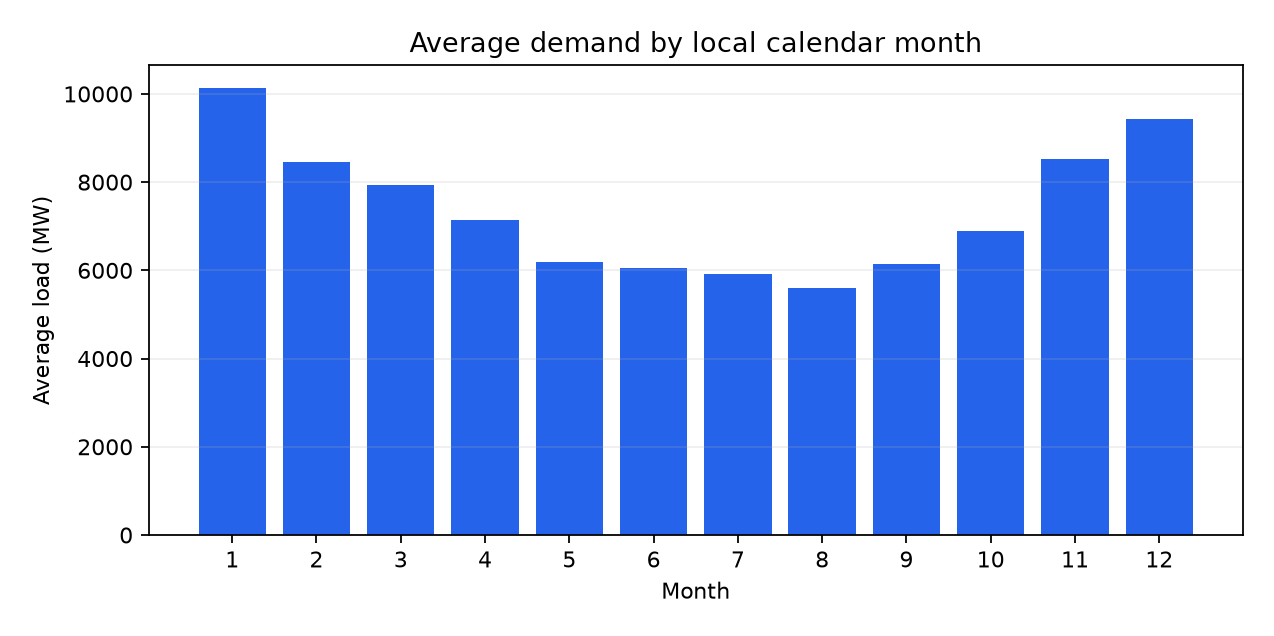

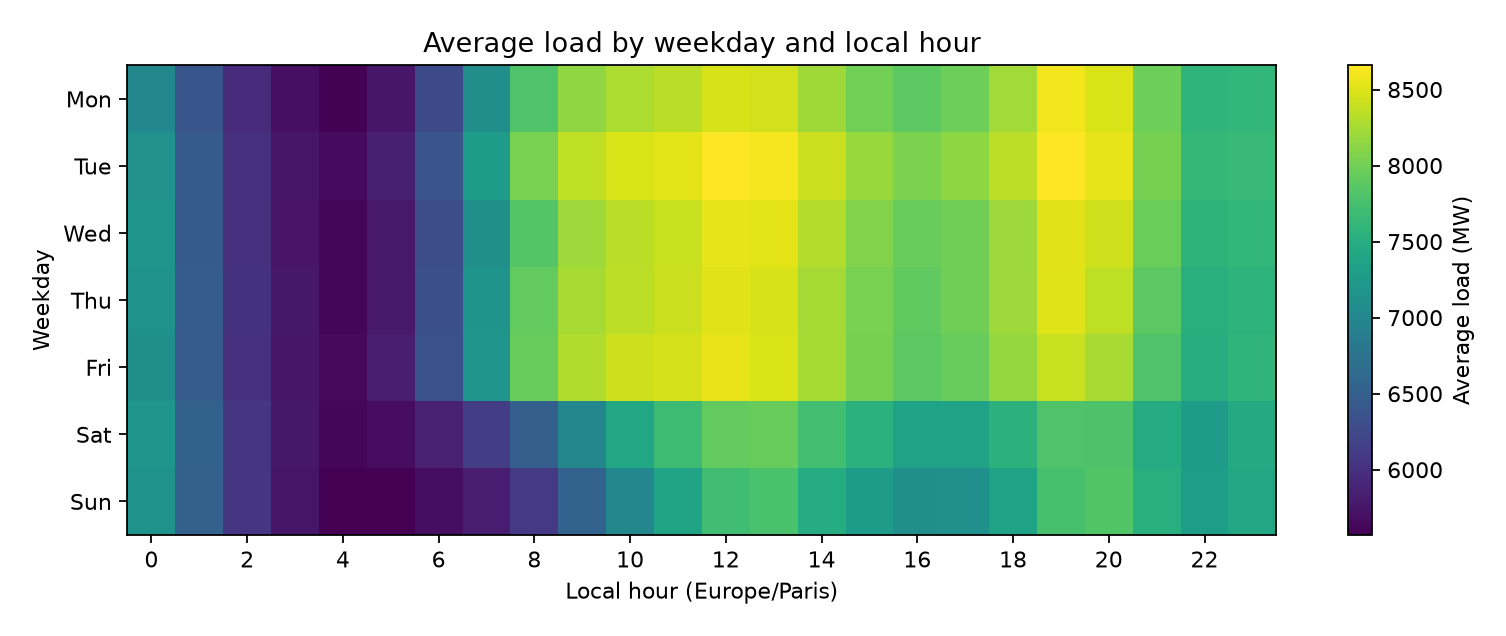

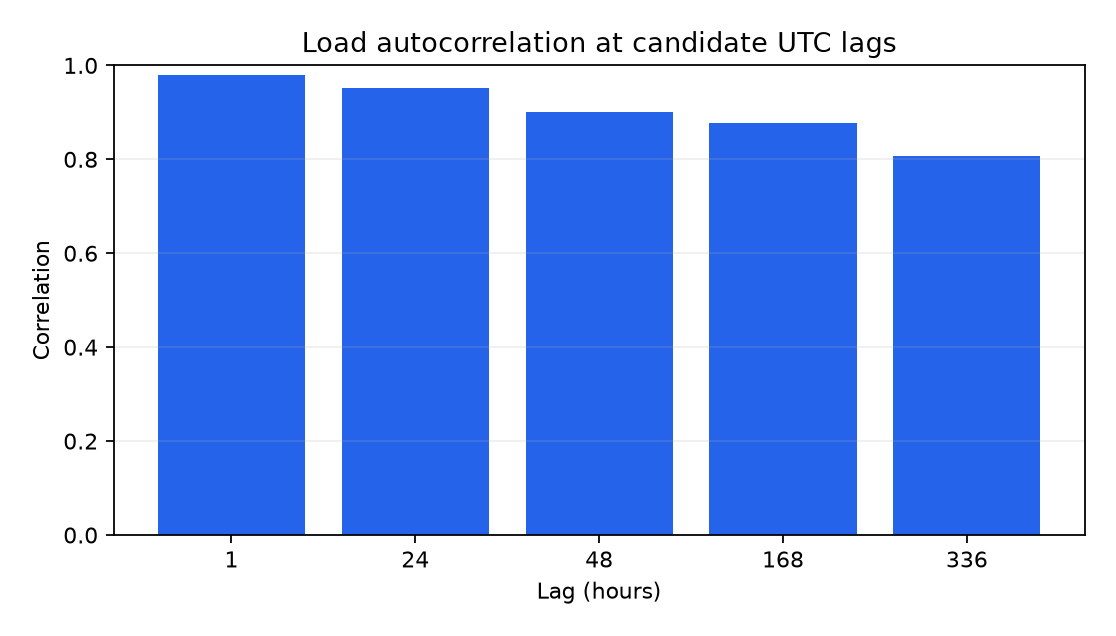

In [6]:
figure_paths, findings = generate_eda_report(hourly, REPORT_DIR)
display(Markdown(findings))
for figure_path in figure_paths:
    display(Image(filename=str(figure_path)))

## Limitations

The RTE source is a revised historical archive, not evidence of when each measurement was available in real time. Correlations are descriptive, not causal. UTC weekly lags also shift relative to the local clock around daylight-saving transitions.